In [4]:
%matplotlib inline
import numpy as np
import pandas as pd
import lightkurve as lk

search = lk.search_lightcurve("TIC 150428135", mission="TESS", author="SPOC", exptime=120)
lcc = search.download_all(download_dir="../data")
print(len(lcc), "sectors downloaded")

37 sectors downloaded


In [5]:
rows = []
for lc in lcc:
    lc_ok = lc.remove_nans().normalize()
    rows.append({
        "sector": int(lc.meta["SECTOR"]),
        "n_cadences": len(lc_ok),
        "t_start": round(float(lc_ok.time.value.min()), 1),
        "t_end": round(float(lc_ok.time.value.max()), 1),
        "scatter_ppm": round(float(np.std(lc_ok.flux.value)) * 1e6),
    })

sector_table = pd.DataFrame(rows).sort_values("sector").reset_index(drop=True)
print(sector_table.to_string())

    sector  n_cadences  t_start   t_end  scatter_ppm
0        1       18279   1325.3  1353.2         1656
1        3       12379   1385.9  1406.2         1605
2        4       14435   1410.9  1436.3         1699
3        5       16983   1438.2  1463.6         1680
4        6       14483   1468.3  1490.0         1688
5        7       16177   1491.7  1516.1         1672
6        8       12849   1518.1  1542.0         1638
7        9       15535   1544.5  1568.5         1694
8       10       14726   1571.5  1595.7         1672
9       11       13491   1600.2  1623.9         1679
10      13       19437   1653.9  1682.4         1812
11      27       13965   2036.3  2058.6         1840
12      28       12499   2061.9  2083.8         1746
13      30       15901   2115.9  2141.4         1625
14      31       16491   2144.5  2169.9         1666
15      33       17458   2201.7  2227.6         1614
16      34       16758   2229.1  2254.1         1628
17      35       13607   2255.9  2280.0       

In [6]:
%matplotlib inline
import glob
import numpy as np
import pandas as pd
import lightkurve as lk

files = sorted(glob.glob("../data/**/*_lc.fits", recursive=True))
print(len(files), "files found")

lcc = lk.LightCurveCollection([lk.read(f) for f in files])
print([int(lc.meta["SECTOR"]) for lc in lcc][:5], "...")
print("sector 1 cadences:", len(lcc[0].remove_nans()))

37 files found
[1, 3, 4, 5, 6] ...
sector 1 cadences: 18279


gap of 3.2 d: BTJD 3946.9 -> 3950.1
gap of 3.3 d: BTJD 3960.3 -> 3963.6
gap of 3.9 d: BTJD 3974.4 -> 3978.3


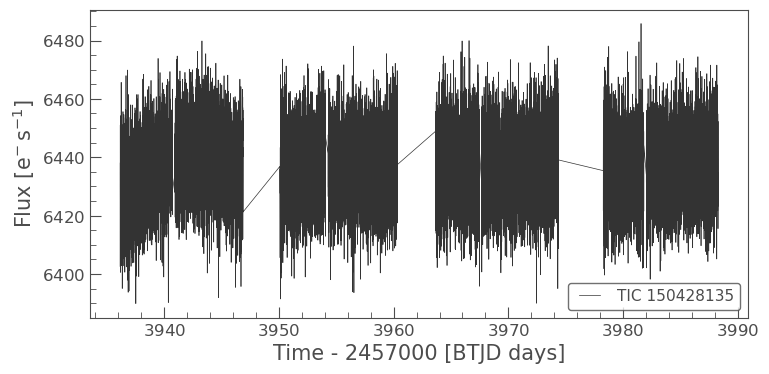

In [7]:
s97 = [lc for lc in lcc if lc.meta["SECTOR"] == 97][0].remove_nans()
t = np.array(s97.time.value, dtype=float)
gaps = np.diff(t)
for i in np.where(gaps > 0.5)[0]:
    print(f"gap of {gaps[i]:.1f} d: BTJD {t[i]:.1f} -> {t[i+1]:.1f}")
s97.plot();

In [8]:
import math

lc1 = lcc[0].remove_nans().normalize()
print("sector:", lc1.meta["SECTOR"])
f = np.array(lc1.flux.value, dtype=float)

med = np.median(f)
robust_sigma = 1.4826 * np.median(np.abs(f - med))
z = (f - med) / robust_sigma

for k in [3, 4, 5, 6]:
    n_up = int(np.sum(z > k))
    n_dn = int(np.sum(z < -k))
    expect = len(z) * 0.5 * math.erfc(k / math.sqrt(2))
    print(f">{k} sigma: {n_up:3d} high, {n_dn:3d} low  (random noise expects about {expect:.1f} per side)")

sector: 1
>3 sigma:  29 high,  17 low  (random noise expects about 24.7 per side)
>4 sigma:   0 high,   0 low  (random noise expects about 0.6 per side)
>5 sigma:   0 high,   0 low  (random noise expects about 0.0 per side)
>6 sigma:   0 high,   0 low  (random noise expects about 0.0 per side)


In [9]:
import math

rows = []
for lc in lcc:
    lc_ok = lc.remove_nans().normalize()
    f = np.array(lc_ok.flux.value, dtype=float)
    med = np.median(f)
    sig = 1.4826 * np.median(np.abs(f - med))
    z = (f - med) / sig
    rows.append({
        "sector": int(lc.meta["SECTOR"]),
        "N": len(z),
        "high>4": int(np.sum(z > 4)),
        "low<-4": int(np.sum(z < -4)),
        "high>5": int(np.sum(z > 5)),
        "low<-5": int(np.sum(z < -5)),
        "expect>4": round(len(z) * 0.5 * math.erfc(4 / math.sqrt(2)), 2),
    })

clip_table = pd.DataFrame(rows).sort_values("sector").reset_index(drop=True)
print(clip_table.to_string())
print("total high>4:", clip_table["high>4"].sum(),
      "| total low<-4:", clip_table["low<-4"].sum(),
      "| expected per side:", round(clip_table["expect>4"].sum(), 1))

    sector      N  high>4  low<-4  high>5  low<-5  expect>4
0        1  18279       0       0       0       0      0.58
1        3  12379       2       0       1       0      0.39
2        4  14435       4       0       1       0      0.46
3        5  16983       3       0       0       0      0.54
4        6  14483      13       0       2       0      0.46
5        7  16177       2       0       1       0      0.51
6        8  12849       3       0       0       0      0.41
7        9  15535       4       0       0       0      0.49
8       10  14726       3       0       0       0      0.47
9       11  13491       0       1       0       0      0.43
10      13  19437       5       3       0       0      0.62
11      27  13965       4       0       0       0      0.44
12      28  12499       3       1       0       0      0.40
13      30  15901       1       1       0       0      0.50
14      31  16491       3       1       1       0      0.52
15      33  17458       3       0       

In [10]:
clip_table.to_csv("../notes/clip_table.csv", index=False)